# Project: Travily - Advanced RAG-Enhanced LangGraph MoE with Backtracking

## I. Project Overview
Travily is a high-performance, domain-specific AI Agent framework designed to orchestrate complex reasoning and data-driven tasks. Built upon a stateful, cyclic architecture via LangGraph and powered by Google Gemini, the system integrates a Retrieval-Augmented Generation (RAG) pipeline into a Mixture of Experts (MoE) model. Instead of relying solely on the parametric knowledge of LLMs, Travily dynamically fetches grounded, domain-specific context from an external knowledge base or search engine. This architectural synergy ensures that specialized agents debate, align, and self-correct using verified facts, resulting in a highly accurate and context-aware final output.

---

## RAG-Enhanced Backtracking

The integration of RAG supports an advanced paradigm of **Fact-Grounded Error Correction and Path Readjustment**:

1. Knowledge-Driven Initialization: When a query enters the system, the RAG component retrieves relevant real-world documents or data chunks, providing a synchronized contextual baseline for all specialized expert nodes.
2. Divergent Expert Generation: Utilizing different model profiles and temperature settings, Expert A (optimized for creative synthesis) and Expert B (optimized for rigid analytical deduction) interpret the retrieved context to form specialized drafts.
3. The Backtracking & Pruning Mechanism: The Evaluator Node analyzes whether the experts' outputs conflict or deviate from the factual baseline provided by the RAG pipeline. If a logical gap or potential hallucination is detected, the workflow triggers a semantic prune.
4. Adaptive Re-Retrieval Loop: Instead of a blind retry, the graph backtracks to the routing and retrieval state. The system leverages the evaluator's feedback to refine the search queries, fetching deeper or alternative context to resolve the dead end.


This iterative process maps perfectly to a Depth-First Search (DFS) with pruning and backtracking, where every step down the reasoning path is strictly gated by factuality and logical consistency.

---

## II. Key Architectural Components
* Knowledge Retriever (RAG): Queries vector databases, structured data sources, or web search tools to inject verified real-time context into the workflow state.
* Router & Dispatcher: Analyzes the user query alongside retrieved context to distribute specialized tasks.
* Specialized MoE Experts: Distinct Gemini agents configured with varying cognitive behaviors to tackle multifaceted domains within the retrieved knowledge space.
* Consistency Evaluator: A strict, deterministic judge that acts as the validation gate, determining whether the experts' responses are aligned with each other and grounded in the retrieved facts.
* Conditional Backtracking Edges: The cyclic routing infrastructure that seamlessly manages state rollbacks, steering the agent back to re-retrieval and regeneration upon validation failure.


## III. Environment Setup & Dependency Installation

Install the required core libraries for LangGraph orchestration, Gemini LLM integration, and Tavily-powered RAG search capabilities.


In [1]:
!pip install langchain-core langchain-google-genai langchain-community tavily-python langgraph


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 24.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 65.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 27.0 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.49.0
    Uninstalling google-auth-2.49.0:
      Successfully uninstalled google-auth-2.49.0
  Attempting uninstall: google-genai
    Found existing installation: google-genai 2.12.1
    Uninstalling google-genai-2.12.1:
      Successfully uninstalled google-genai-2.12.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [langchain-community]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1

In [1]:
import os
from typing import TypedDict
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_community.tools.tavily_search import TavilyAnswer
from langgraph.graph import StateGraph, END


/tmp/ipykernel_1591/1490238917.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilyAnswer


In [2]:
# Google Gemini and Tavily API Key
from google.colab import userdata
os.environ["GOOGLE_API_KEY"] = userdata.get('GeminiAPI')
os.environ["TAVILY_API_KEY"] = userdata.get('tavily')

## IV. RAG Configuration

In [3]:
# =====================================================================
# Define the Search Tool for RAG Integration
# =====================================================================
# A built-in tool that dynamically fetches and summarizes real-time
# search results from the web based on the user's query.
search_tool = TavilyAnswer(max_results=3)


/tmp/ipykernel_1591/2213298566.py:6: LangChainDeprecationWarning: The class `TavilyAnswer` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  search_tool = TavilyAnswer(max_results=3)


## V. State Schema Definition


In [4]:
# =====================================================================
# State Schema Definition
# =====================================================================
class RAGMoEState(TypedDict):
    question: str          # The original user query
    context: str           # Fresh RAG knowledge retrieved via real-time web search
    expert_a_answer: str   # Output from Expert A
    expert_b_answer: str   # Output from Expert B
    is_consistent: bool    # Validation result determining workflow path
    feedback: str          # Feedback message for backtracking / Final answer storage
    retry_count: int       # Counter to track backtracking loops



## VI. Model Initialization

In [5]:
# =====================================================================
# Model Initialization
# =====================================================================
# Configure the expert agents and evaluators with designated model tiers and temperatures.
expert_a = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0.7)
expert_b = ChatGoogleGenerativeAI(model="gemini-3.6-flash", temperature=0.4)
evaluator_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0.0)
judge_llm = ChatGoogleGenerativeAI(model="gemini-3.6-flash", temperature=0.2)

## VII. Define Agent Nodes & Workflow Functions


In [6]:
# =====================================================================
# Define Agent Nodes & Workflow Functions
# =====================================================================

def web_search_node(state: RAGMoEState) -> dict:
    """
    [RAG Node] Performs a real-time web search based on the user query
    and saves the retrieved factual text into the workflow state.
    """
    question = state["question"]
    print(f"[RAG Search Node] Searching the web for real-time information: '{question}'")

    # Execute real-time web retrieval
    search_result = search_tool.invoke({"query": question})

    return {"context": search_result}


def generate_drafts_node(state: RAGMoEState) -> dict:
    """
    [Expert Node] Generates initial analytical drafts from specialized experts
    grounded firmly in the retrieved RAG web data.
    """
    question = state["question"]
    context = state["context"]
    feedback = state.get("feedback", "")
    retry_count = state.get("retry_count", 0)

    # Design fact-grounded prompt template
    prompt_content = """You are a professional analyst tasked with answering the question based strictly on the provided references (Context).

[References (Real-time Web Search Results)]
{context}

Question: {question}"""

    if feedback:
        print(f"\n[Retry #{retry_count}] Regenerating responses by blending retrieved data with evaluation feedback...")
        prompt_content += "\n\nCRITICAL FEEDBACK: Please refine your logic to bridge the gap and align with the following instructions:\n{feedback}"
    else:
        print(f"\n[Attempt #1] Experts A and B are initiating analysis based on the retrieved context.")

    prompt = ChatPromptTemplate.from_template(prompt_content)
    chain_a = prompt | expert_a | StrOutputParser()
    chain_b = prompt | expert_b | StrOutputParser()

    res_a = chain_a.invoke({"question": question, "context": context, "feedback": feedback})
    res_b = chain_b.invoke({"question": question, "context": context, "feedback": feedback})

    return {
        "expert_a_answer": res_a,
        "expert_b_answer": res_b,
        "retry_count": retry_count + 1
    }


def verify_consistency_node(state: RAGMoEState) -> dict:
    """
    [Verification Node] Cross-examines and triangulates the original retrieved context
    with the responses from both experts to ensure absolute factual alignment.
    """
    print("[Verification Node] Auditing factual consistency between retrieved context and expert responses...")

    verify_prompt = ChatPromptTemplate.from_messages([
        ("system", "You are a chief auditor responsible for verifying whether the expert responses align with each other and are completely grounded in the provided factual context."),
        ("human", """[References (Factual Grounding)]
{context}

[Expert A's Response]
{expert_a_answer}

[Expert B's Response]
{expert_b_answer}

Are there any contradictions, distortions of fact, or significant logical gaps that require alignment between the two experts?
You must respond strictly in the following JSON format. Do not include any other explanatory text.

{{
    "is_consistent": true or false,
    "feedback": "If false, provide specific instructions on how both experts should complement each other to close the gap. If true, leave it as an empty string."
}}""")
    ])

    class VerificationResult(TypedDict):
        is_consistent: bool
        feedback: str

    structured_evaluator = evaluator_llm.with_structured_output(VerificationResult)
    verify_chain = verify_prompt | structured_evaluator

    result = verify_chain.invoke(state)
    return {
        "is_consistent": result["is_consistent"],
        "feedback": result["feedback"]
    }


def final_judge_node(state: RAGMoEState) -> dict:
    """
    [Synthesis Node] Synthesizes the fully audited and verified factual data
    into a comprehensive final master briefing.
    """
    print("[Final Judge Node] Compiling fully verified data into the final master briefing document...")

    judge_prompt = ChatPromptTemplate.from_template("""[Verified Factual Data]
{context}

[Expert A's Report]
{expert_a_answer}

[Expert B's Report]
{expert_b_answer}

Synthesize these brilliant insights into a highly cohesive, well-structured, and readable 'Final Master Response' for the user.""")

    judge_chain = judge_prompt | judge_llm | StrOutputParser()
    final_answer = judge_chain.invoke(state)

    return {"feedback": final_answer}


## VIII. Graph Construction & Compilation

In [7]:
# =====================================================================
# Graph Construction & Compilation
# =====================================================================
def route_after_verification(state: RAGMoEState) -> str:
    """Determines whether to trigger a backtracking loop or proceed to final synthesis."""
    if state["retry_count"] >= 2:
        print("[Routing Edge] Maximum retry limit reached. Bypassing further loops.")
        return "proceed"

    if state["is_consistent"]:
        print("[Routing Edge] Fact-check and consistency verification passed! Moving forward to final synthesis.")
        return "proceed"
    else:
        print("[Routing Edge] Factual inconsistency or logical gap detected. Triggering Backtracking Loop!")
        return "retry"

# Initialize the workflow graph with our custom state schema
workflow = StateGraph(RAGMoEState)

# Register workflow nodes
workflow.add_node("web_search", web_search_node)
workflow.add_node("generate_drafts", generate_drafts_node)
workflow.add_node("verify_consistency", verify_consistency_node)
workflow.add_node("final_judge", final_judge_node)

# Set up the sequential edge flow
workflow.set_entry_point("web_search")  # 1. Initiate with real-time web retrieval
workflow.add_edge("web_search", "generate_drafts")  # 2. Forward retrieved context to generate drafts
workflow.add_edge("generate_drafts", "verify_consistency")  # 3. Submit drafts to the auditor node

# 4. Inject conditional backtracking logic based on auditing outcome
workflow.add_conditional_edges(
    "verify_consistency",
    route_after_verification,
    {
        "retry": "generate_drafts",  # Route back to regeneration node on validation failure
        "proceed": "final_judge"     # Advance to synthesis node on validation success
    }
)

# Connect the final node to the end of the workflow execution
workflow.add_edge("final_judge", END)

# Compile the workflow configuration into a runnable application
app = workflow.compile()


## VIIII. Graph Visualization

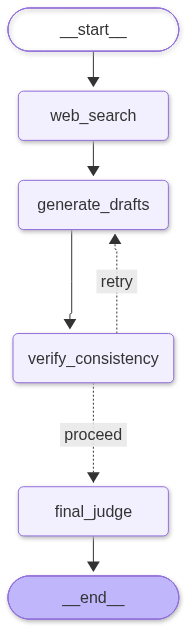

In [8]:
# =====================================================================
# Workflow Graph Visualization
# =====================================================================
from IPython.display import Image, display

try:
    # Generate and display the architectural graph structure using Mermaid
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    # Fallback message if graphviz or required visualization prerequisites are missing
    print(f"Graph visualization failed: {e}")
    print("Please ensure pygraphviz or alternative visualization prerequisites are installed.")


## X. Workflow Execution & Testing

In [9]:
# =====================================================================
# Workflow Execution & Testing
# =====================================================================

if __name__ == "__main__":
    # Test query demanding fresh, real-time knowledge to assess the RAG + MoE pipeline
    test_question = "Analyze the core trends in recent AI agent technologies announced by OpenAI and Anthropic, and compare the strategic differences in their directions."

    print("--- Activating RAG + MoE + Backtracking Hybrid Agent ---")
    initial_state = {
        "question": test_question,
        "retry_count": 0,
        "feedback": "",
        "context": ""
    }

    # Run the compiled hybrid graph workflow
    final_result = app.invoke(initial_state)

    print("\n==================== Final Fact-Checked Master Report ====================\n")
    print(final_result["feedback"])


--- Activating RAG + MoE + Backtracking Hybrid Agent ---
[RAG Search Node] Searching the web for real-time information: 'Analyze the core trends in recent AI agent technologies announced by OpenAI and Anthropic, and compare the strategic differences in their directions.'

[Attempt #1] Experts A and B are initiating analysis based on the retrieved context.


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[Verification Node] Auditing factual consistency between retrieved context and expert responses...


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[Routing Edge] Fact-check and consistency verification passed! Moving forward to final synthesis.
[Final Judge Node] Compiling fully verified data into the final master briefing document...


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



==================== Final Fact-Checked Master Report ====================

# Strategic Directions in AI Agent Technology: Anthropic vs. OpenAI

## Executive Summary
The rapid evolution of AI agent technologies marks a critical juncture in artificial intelligence, where systems are moving beyond text generation to actively execute tasks, interact with external systems, and reason across complex workflows. Both **Anthropic** and **OpenAI** are vying to shape the future of this AI agent ecosystem. However, their strategic directions represent fundamentally different philosophies: **Anthropic is betting on open standards, safety, and interoperability**, while **OpenAI is betting on vertical integration, end-to-end control, and ecosystem maturity**.

---

## Core Trends in AI Agent Technologies
Across the landscape, the overarching trend is expanding the reach and utility of AI agents by enhancing how seamlessly they connect with models, data sources, developer tools, and user interfaces.